# 3. 多分枝汇聚

上文提到了`扇出（Fan-out）`，它是指像打开扇子一样，由一个上游节点分发出多个下游分支。

与之相对，`扇入（Fan-in）`是指像合拢扇子一样，多个上游分支汇聚到同一个下游节点。

`Fan-out` 对应的是“分支结构”，`Fan-in` 对应的是“多分支汇聚结构”。

## 3.1. 静态扇入
在计算机中，“与”表示两个或多个条件同时满足，而“或”表示两个或多个条件任意一个满足。

当多个上游分支同时汇入同一个下游节点时，根据触发条件的不同，可以分成两种情况：

- “与”触发：上游所有分支全部到达才可触发下游节点
- “或”触发：任意一个分支到达，都可以触发下游节点
需要注意，这里的 “与 / 或” 只是帮助理解的类比，并不是 LangGraph 的官方术语。

### 3.1.1 “与”触发：等待所有上游分支到达

这是多分支汇聚中最常见的情况。

LangGraph 的计算图是在一系列超步中完成的，如果能看到每个节点实例运行时的超步编号，则节点执行顺序一目了然。

LangGraph 的节点可以通过名为 `config` 的有名参数获取运行时配置

`config` 的元数据中记录了当前节点所在的 `SuperStep` 序号，可以通过下面的方式获取：

```python
config["metadata"]["langgraph_step"]
```

In [5]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_core.runnables import RunnableConfig

from loguru import logger


class EmptyState(TypedDict):
    pass


def node_a(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_a 被触发", cur_step)
    return {}


def node_b(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_b 被触发", cur_step)
    return {}


def node_c(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_c 被触发", cur_step)
    return {}


def node_d(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_d 被触发", cur_step)
    return {}


def node_e(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_e 被触发", cur_step)
    return {}

2026-10-15 11:15:11.299 | INFO     | __main__:node_a:12 - cur_step: 1, node_a 被触发
2026-10-15 11:15:11.300 | INFO     | __main__:node_b:17 - cur_step: 2, node_b 被触发
2026-10-15 11:15:11.302 | INFO     | __main__:node_c:22 - cur_step: 2, node_c 被触发
2026-10-15 11:15:11.303 | INFO     | __main__:node_d:27 - cur_step: 3, node_d 被触发
2026-10-15 11:15:11.304 | INFO     | __main__:node_e:32 - cur_step: 4, node_e 被触发


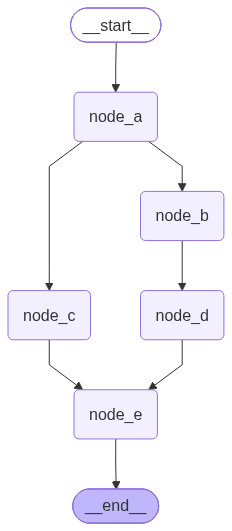

In [6]:
builder = StateGraph(state_schema=EmptyState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_node("node_d", node_d)
builder.add_node("node_e", node_e)

builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_a", "node_c")
builder.add_edge("node_b", "node_d")
builder.add_edge(["node_c", "node_d"], "node_e")

graph = builder.compile()
graph.invoke({})

from IPython.display import display

display(graph)

由运行结果可知：

- `node_a` 在第 1 个超步执行；
- `node_b` 和 `node_c` 在第 2 个超步并行执行；
- `node_d` 在第 3 个超步执行；
- `node_e` 在第 4 个超步执行。

虽然 `node_c` 在第 2 个超步已经执行完成，但是 `node_e` 并不会立刻触发。 因为这里使用的是：

```python
builder.add_edge(["node_c", "node_d"], "node_e")
```
这表示 `node_e` 需要等待 `node_c` 和 `node_d` 两个上游节点全部完成后，才会被触发一次。

因此，这种写法对应的是 “与”触发：等待所有上游分支到达方可触发。

### 3.1.2 “或”触发：任意上游分支到达即可触发
另一种情况是：多个上游分支分别连接到同一个下游节点，但它们之间没有显式的同步等待关系。

2026-10-15 11:15:20.173 | INFO     | __main__:node_a:12 - cur_step: 1, node_a 被触发
2026-10-15 11:15:20.174 | INFO     | __main__:node_b:17 - cur_step: 2, node_b 被触发
2026-10-15 11:15:20.176 | INFO     | __main__:node_c:22 - cur_step: 2, node_c 被触发
2026-10-15 11:15:20.177 | INFO     | __main__:node_d:27 - cur_step: 3, node_d 被触发
2026-10-15 11:15:20.178 | INFO     | __main__:node_e:32 - cur_step: 3, node_e 被触发
2026-10-15 11:15:20.178 | INFO     | __main__:node_e:32 - cur_step: 4, node_e 被触发


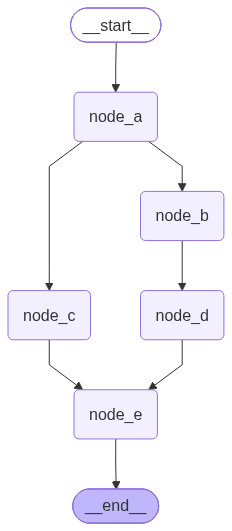

In [7]:
builder = StateGraph(state_schema=EmptyState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_node("node_d", node_d)
builder.add_node("node_e", node_e)

builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_a", "node_c")
builder.add_edge("node_b", "node_d")

# 独立触发：node_c 完成后可以触发 node_e
builder.add_edge("node_c", "node_e")
# 独立触发：node_d 完成后可以触发 node_e
builder.add_edge("node_d", "node_e")

graph = builder.compile()
graph.invoke({})

from IPython.display import display

display(graph)

从运行结果可以看出，`node_e` 被触发了两次：

- `node_c` 在第 2 个超步执行完成后，触发 `node_e` 在第 3 个超步执行；
- `node_d` 在第 3 个超步执行完成后，再次触发 `node_e` 在第 4 个超步执行。

原因是这里使用了两条独立的边：

```python
builder.add_edge("node_c", "node_e")
builder.add_edge("node_d", "node_e")
```
这表示 `node_c` 和 `node_d` 都可以分别触发 node_e，它们之间没有同步等待关系。

因此，这种写法对应的是 独立触发，也可以类比为 “或”触发。

需要特别注意：

```python
builder.add_edge(["node_c", "node_d"], "node_e")
```
和
```python
builder.add_edge("node_c", "node_e")
builder.add_edge("node_d", "node_e")
```
不是等价写法。

前者表示 等待多个上游全部完成后才触发一次； 后者表示 多个上游分支分别独立触发下游节点。

2026-10-15 11:16:35.108 | INFO     | __main__:node_a:12 - cur_step: 1, node_a 被触发
2026-10-15 11:16:35.109 | INFO     | __main__:node_c:22 - cur_step: 2, node_c 被触发
2026-10-15 11:16:35.110 | INFO     | __main__:node_d:27 - cur_step: 2, node_d 被触发
2026-10-15 11:16:35.112 | INFO     | __main__:node_e:32 - cur_step: 3, node_e 被触发


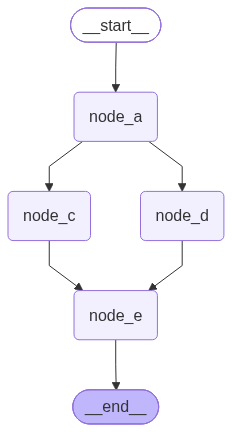

In [10]:
builder = StateGraph(state_schema=EmptyState)
builder.add_node("node_a", node_a)
builder.add_node("node_c", node_c)
builder.add_node("node_d", node_d)
builder.add_node("node_e", node_e)

builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_c")
builder.add_edge("node_a", "node_d")

# 独立触发：node_c 完成后可以触发 node_e
builder.add_edge("node_c", "node_e")
# 独立触发：node_d 完成后可以触发 node_e
builder.add_edge("node_d", "node_e")

graph = builder.compile()
graph.invoke({})

from IPython.display import display

display(graph)

## 3.2 动态扇入-MapReduce结构
在上文我们通过 `Send` 动态生成了多个下游任务。

这种模式本质上是一种动态扇出：根据运行时数据，将一个任务拆分为多个子任务，并分别发送给下游节点处理。

如果这些子任务分别产生中间结果，并在后续通过 `Reducer` 进行合并，也就是重新 扇入 到一个下游节点中，最终得到统一的结果，那么就构成了典型的 `MapReduce` 结构。

`MapReduce` 是大数据计算中的经典模型，通常包含两个核心阶段：

- `Map`：映射阶段 将输入数据映射为中间结果。

    在 LangGraph 中，可以理解为通过 `Send` 将子任务分发给多个 `mapper` 节点实例，每个节点实例独立完成局部计算：将部分输入数据映射为中间结果。

- `Reduce`：归约阶段 将多个子任务产生的中间结果进行汇总、合并或聚合，得到最终结果。

    在 LangGraph 中，通常由一个特定的 `Reducer` 节点完成归约：它接收上游 `mapper` 节点实例产生的中间结果，处理后得到计算图的最终输出。

本节实现一个经典的词频统计任务。

需要注意，本节示例中没有单独实现一个 `Shuffle` 节点，而是把 `Shuffle / Group` 的逻辑也放在了 `reducer_node` 中完成。

在下面的示例中，我们用 `Send` 动态派发任务，创建了多个 `mapper_node` 实例。

每个 `mapper_node` 实例负责处理一条输入数据，并输出中间产物：键值对。

随后，下游的 `reducer_node` 收集所有中间结果，完成 `Shuffle / Group` 和最终的 `Reduce` 聚合。

2026-10-15 11:23:57.605 | INFO     | __main__:reducer_node:45 - reducer entries: [('hello', 1), ('world', 1), ('hello', 1), ('Ren', 1), ('hello', 1), ('LLM', 1)]
2026-10-15 11:23:57.605 | INFO     | __main__:reducer_node:55 - reducer shuffle entries: {'hello': [1, 1, 1], 'world': [1], 'Ren': [1], 'LLM': [1]}


{'input_values': ['hello world', 'hello Ren', 'hello LLM'], 'entries': [('hello', 1), ('world', 1), ('hello', 1), ('Ren', 1), ('hello', 1), ('LLM', 1)], 'word_counts': {'hello': 3, 'world': 1, 'Ren': 1, 'LLM': 1}}


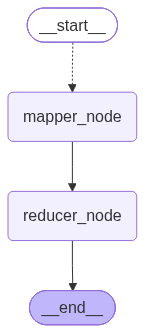

In [2]:
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
from _collections_abc import Sequence
from operator import add

from loguru import logger


class OverAllState(TypedDict):
    input_values: list[str]
    entries: Annotated[list[tuple[str, int]], add]
    word_counts: dict[str, int]


def router_map(state: OverAllState) -> Sequence[Send]:
    input_values = state["input_values"]

    tasks = []
    # 对于每一个句子分发一个mapper_node实例
    for input_value in input_values:
        tasks.append(Send("mapper_node", {"input_value": input_value}))

    return tasks


class MapperInputState(TypedDict):
    input_value: str


def mapper_node(state: MapperInputState) -> OverAllState:
    input_value = state["input_value"]
    words = input_value.split(" ")
    entries = []

    for word in words:
        entries.append((word, 1))

    return {
        "entries": entries
    }


def reducer_node(state: OverAllState) -> OverAllState:
    entries = state["entries"]
    logger.info("reducer entries: {}", entries)

    shuffle_dict = {}

    for k, v in entries:
        if k not in shuffle_dict:
            shuffle_dict[k] = [v]
        else:
            shuffle_dict[k].append(v)

    logger.info("reducer shuffle entries: {}", shuffle_dict)

    reduce_dict = {}

    for k, v in shuffle_dict.items():
        reduce_dict[k] = sum(v)

    return {
        "word_counts": reduce_dict
    }


builder = StateGraph(state_schema=OverAllState)
builder.add_node("mapper_node", mapper_node)
builder.add_node("reducer_node", reducer_node)

builder.add_conditional_edges(START, router_map, path_map=["mapper_node"])
builder.add_edge("mapper_node", "reducer_node")
builder.add_edge("reducer_node", END)

graph = builder.compile()
word_counts = graph.invoke(
    {"input_values": [
        "hello world",
        "hello Ren",
        "hello LLM"
    ]}
)

print(word_counts)

from IPython.display import display

display(graph)